# Protocolo de validación y métricas

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
panel = C.load_panel()
print(panel.shape, "| orígenes de prueba:", len(C.test_origins()), C.test_origins()[0].date(), "->", C.test_origins()[-1].date())

(2630400, 3) | orígenes de prueba: 92 2014-10-01 -> 2014-12-31


## 1. Protocolo
- **Origen móvil**: cada día de prueba a las 00:00 el modelo recibe `history = panel[ds < origen]` (datos hasta las 23:00 del día anterior) y pronostica 24 h. 92 orígenes × 24 h × 100 clientes = 220 800 pronósticos.
- **Pesos**: se entrenan una sola vez con datos hasta 2014-09-30 (el modelo llega a `backtest` ya entrenado, o `fit=True`).
- **Reentrenamiento**: `retrain="monthly"` refit el 1-oct, 1-nov y 1-dic con ventana expansiva (`ds < origen`).
- La interfaz exige que `predict` devuelva exactamente las 24 horas desde el origen (se verifica con `assert`).

## 2. Pruebas de cordura del protocolo

In [2]:
class Oracle(C.ForecastModel):   # hace trampa a propósito: lee el futuro del panel completo
    name = "oracle"
    def fit(self, tr): return self
    def predict(self, history, origin):
        ds = pd.date_range(origin, periods=C.H, freq="h")
        return panel[panel.ds.isin(ds)].rename(columns={"y": "y_hat"})[["unique_id", "ds", "y_hat"]]
p = C.backtest(Oracle(), panel); path = C.save_preds(p, "_oracle")
r = C.evaluate(path, panel); print("Oráculo -> MAE", r["global"]["MAE"], "| MASE", r["global"]["MASE"]); assert r["global"]["MAE"] < 1e-9
path.unlink()

class Spy(C.ForecastModel):      # registra lo máximo que ve del panel y cuántas veces se reentrena
    name = "spy"; fits = []; seen_max = []
    def fit(self, tr): Spy.fits.append(tr.ds.max()); return self
    def predict(self, history, origin):
        Spy.seen_max.append((origin, history.ds.max()))
        ds = pd.date_range(origin, periods=C.H, freq="h")
        return pd.DataFrame({"unique_id": np.repeat(history.unique_id.unique(), C.H), "ds": np.tile(ds, history.unique_id.nunique()), "y_hat": 0.0})
C.backtest(Spy(), panel, retrain="monthly")
assert all(m < o for o, m in Spy.seen_max) and all(m == o - pd.Timedelta("1h") for o, m in Spy.seen_max)
print("Historia máxima vista = origen - 1 h en los 92 orígenes. Reentrenos con datos hasta:", [str(x) for x in Spy.fits])
assert len(Spy.fits) == 3

Oráculo -> MAE 0.0 | MASE 0.0


Historia máxima vista = origen - 1 h en los 92 orígenes. Reentrenos con datos hasta: ['2014-09-30 23:00:00', '2014-10-31 23:00:00', '2014-11-30 23:00:00']


## 3. Seasonal naive de referencia (24 h y 168 h)

In [3]:
class SeasonalNaive(C.ForecastModel):
    def __init__(self, m): self.m, self.name = m, f"snaive_{m}h_demo"
    def fit(self, tr): return self
    def predict(self, history, origin):
        k = int(np.ceil(C.H / self.m)) if self.m < C.H else 1       # saltos hacia atrás para quedar en el pasado
        shift = pd.Timedelta(hours=self.m * k)
        src = pd.date_range(origin, periods=C.H, freq="h") - shift
        h = history[history.ds.isin(src)].copy(); h["ds"] += shift
        return h.rename(columns={"y": "y_hat"})[["unique_id", "ds", "y_hat"]]
res = {}
for m in (24, 168):
    mod = SeasonalNaive(m); res[mod.name] = C.evaluate(C.save_preds(C.backtest(mod, panel), mod.name), panel)
tab = pd.DataFrame({k: v["global"] for k, v in res.items()}).T
tab["MASE Navidad"] = [v["xmas"]["MASE"] for v in res.values()]
display(tab.round(4))

,MAE,RMSE,WAPE,MAPE,MAPE_n_excluidos,MASE,MASE Navidad
snaive_24h_demo,45.8698,236.3032,0.085,0.1397,3018.0,1.0875,2.4717
snaive_168h_demo,43.1660,192.4684,0.080,0.1109,3018.0,1.1494,1.6672


Estas filas son solo para validar el protocolo; los baselines oficiales (Naive, seasonal naive, MSTL/AutoETS) se hacen con StatsForecast en el CP3 y sobrescriben estos archivos de demostración (`*_demo.parquet`).

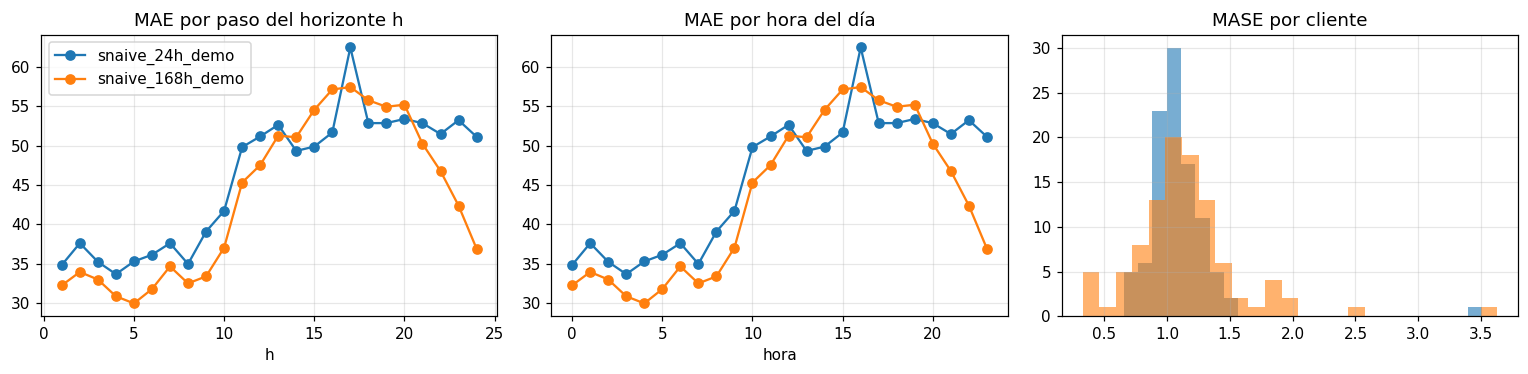

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
for k, v in res.items():
    axs[0].plot(v["by_h"].index, v["by_h"]["MAE"], "o-", label=k); axs[1].plot(v["by_hour"].index, v["by_hour"]["MAE"], "o-", label=k)
    axs[2].hist(v["by_client"]["MASE"], bins=25, alpha=.6, label=k)
axs[0].set_title("MAE por paso del horizonte h"); axs[0].set_xlabel("h"); axs[0].legend()
axs[1].set_title("MAE por hora del día"); axs[1].set_xlabel("hora"); axs[2].set_title("MASE por cliente")
plt.tight_layout(); plt.savefig("figs/backtest_demo.png"); plt.show()

## 4. Métricas y MAPE con consumo cercano a cero

In [5]:
mod = SeasonalNaive(168); p = pd.read_parquet(C.PRED_DIR / f"{mod.name}.parquet").merge(panel, on=["unique_id", "ds"])
p["ape"] = (p.y_hat - p.y).abs() / p.y.replace(0, np.nan)
print("Horas de prueba con y == 0:", int((p.y == 0).sum()), f"({(p.y == 0).mean():.3%}) -> excluidas del MAPE")
bins = pd.cut(p.y, [0, .1, 1, 10, 100, np.inf], include_lowest=False)
print(p.groupby(bins, observed=True).ape.agg(["count", "mean", "median", "max"]).round(2))
print("MAPE (media) =", round(p.ape.mean(), 3), "| mediana de APE =", round(p.ape.median(), 3), "| WAPE =", round(res[mod.name]["global"]["WAPE"], 3))

Horas de prueba con y == 0: 3018 (1.367%) -> excluidas del MAPE
                count   mean  median     max
y                                           
(0.1, 1.0]         18  25.76    1.00  446.64
(1.0, 10.0]      2686   0.36    0.09  180.13
(10.0, 100.0]   78879   0.13    0.07   14.25
(100.0, inf]   136199   0.09    0.06    9.42
MAPE (media) = 0.111 | mediana de APE = 0.061 | WAPE = 0.08
